# Cambodia STEPS — Model Training, Evaluation & Explainability

**Input :** `newdata/cambodia_diabetes_final_clean.csv` — 873 records, 19 features  
**Pipeline:**
```
Load Data → 70/15/15 Split → StandardScaler → SMOTE (Train Only)
  → Train 4 Individual Models → Evaluate on Validation → Select Top 3 by F1
  → Build Dynamic Ensemble → Final Best Model by Validation F1
  → Threshold Tuning (maximise Recall, F1 ≥ floor)
  → Final Test Evaluation → SHAP Explainability
  → Risk Categories → Patient Dashboard (Gemini Recommendations)
```

**Evaluation Metrics:**
| Role | Metric |
|---|---|
| Clinical priority | **Recall** (minimise missed diabetics) |
| Model selection | **Validation F1** (primary) |
| Supporting | Accuracy, Precision |

**Saves:** `best_model.pkl` · `scaler.pkl` · `threshold.pkl` · `feature_names.pkl`

## 1. Imports & Configuration

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
import shap

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
TARGET_COL   = 'Diabetes_binary'
DATA_DIR     = '../newdata/'

FEATURE_GROUPS = {
    'Health Status':                 ['BMI','Waist_cm','HighBP','HighChol'],
    'Lifestyle & Healthcare Access': ['Smoking','AlcoholUse','HvyAlcoholConsump','PhysActivity',
                                      'SedentaryMinutes','Fruits','Veggies',],
    'Demographic':                   ['Sex','Age','Education'],
}

FEATURE_LABELS = {
    'Sex': 'Sex (Male=1)',
    'Age': 'Age (years)',
    'Education': 'Education level',
    'BMI': 'BMI',
    'Waist_cm': 'Waist circumference (cm)',
    'HighBP': 'High blood pressure',
    'HighChol': 'High cholesterol (proxy)',
    'Smoking': 'Smoker (current/former)',
    'AlcoholUse': 'Alcohol use',
    'HvyAlcoholConsump': 'Heavy alcohol consumption',
    'PhysActivity': 'Physical activity',
    'SedentaryMinutes': 'Daily sedentary time (min)',
    'Fruits': 'Fruit consumption',
    'Veggies': 'Vegetable consumption',
}

RISK_COLORS = {'Low': '#4CAF50', 'Moderate': '#FF9800', 'High': '#F44336'}

print('Libraries loaded.')

Libraries loaded.


## 2. Gemini API Setup

The recommendation panel calls Gemini to convert model outputs into plain-language lifestyle education.
Gemini does **not** perform diagnosis — it only explains what the model found.

In [2]:
from dotenv import load_dotenv
from google import genai

load_dotenv('../.env')
GEMINI_API_KEY = os.getenv('GEMINI_API_KEY', '')
gemini_client  = genai.Client(api_key=GEMINI_API_KEY) if GEMINI_API_KEY else None

def get_gemini_recommendations(prob, risk, patient_profile, top_risk_factors, protective_factors):
    """Call Gemini 1.5-flash and return structured health education."""
    payload = {
        'risk_probability':  round(float(prob), 2),
        'risk_level':        risk,
        'patient_profile':   patient_profile,
        'top_risk_factors':  top_risk_factors,
        'protective_factors': protective_factors,
        'instruction':       'Provide simple lifestyle education only. Do not diagnose.',
    }
    prompt = (
        'You are a friendly health educator. Based on this diabetes risk assessment, '
        'provide lifestyle guidance in simple language.\n\n'
        + json.dumps(payload, indent=2)
        + '\n\nRespond ONLY in this exact JSON format (no markdown wrapper):\n'
        '{\n  "explanation": "2-3 sentences explaining the risk in plain language",\n'
        '  "recommendations": ["Rec 1", "Rec 2", "Rec 3", "Rec 4"],\n'
        '  "safety_reminder": "One sentence reminding this is educational only"\n}'
    )
    try:
        response = gemini_client.models.generate_content(
            model='gemini-1.5-flash', contents=prompt
        )
        text = response.text.strip()
        if '```' in text:
            text = text.split('```')[1]
            if text.startswith('json'): text = text[4:]
        return json.loads(text.strip())
    except Exception:
        return {
            'explanation': f'Your predicted diabetes risk is {prob*100:.0f}% ({risk} level). '
                           'Several lifestyle and health factors contribute to this result.',
            'recommendations': [
                'Maintain a balanced diet rich in vegetables and whole grains',
                'Engage in at least 150 minutes of moderate exercise per week',
                'Monitor blood pressure and blood glucose regularly',
                'Consult a healthcare professional for personalized advice',
            ],
            'safety_reminder': 'This is for educational awareness only — not a medical diagnosis.',
        }

print(f'Gemini client ready: {"Yes" if gemini_client else "No API key set"}')

Gemini client ready: Yes


## 3. Load Preprocessed Data

In [3]:
df = pd.read_csv(DATA_DIR + 'cambodia_diabetes_final_clean.csv')
print(f'Dataset: {df.shape[0]} records  x  {df.shape[1]} columns')
print(f'Features: {df.shape[1]-1}')
print(f'Class distribution:\n{df[TARGET_COL].value_counts()}')
print(f'Positive rate (diabetes): {df[TARGET_COL].mean()*100:.1f}%')
df.head(3)

Dataset: 873 records  x  15 columns
Features: 14
Class distribution:
Diabetes_binary
0    751
1    122
Name: count, dtype: int64
Positive rate (diabetes): 14.0%


,Diabetes_binary,Sex,Age,Education,BMI,Waist_cm,HighBP,HighChol,Smoker,AlcoholUse,HvyAlcoholConsump,PhysActivity,SedentaryMinutes,Fruits,Veggies
0,0,1,29,5,25.5,86.0,0,1,1,1,0,1,240,0,1
1,0,1,26,2,23.4,83.0,0,1,0,1,0,1,180,1,1
2,0,1,34,4,24.4,90.0,0,1,1,1,0,1,150,1,1


## 4. Stratified 70 / 15 / 15 Split

Validation and Test remain **100 % real** Cambodian data so reported metrics reflect true real-world performance.

            Rows  Diabetes  No Diabetes  % Positive
Split                                              
Train        611        85          526        13.9
Validation   131        19          112        14.5
Test         131        18          113        13.7


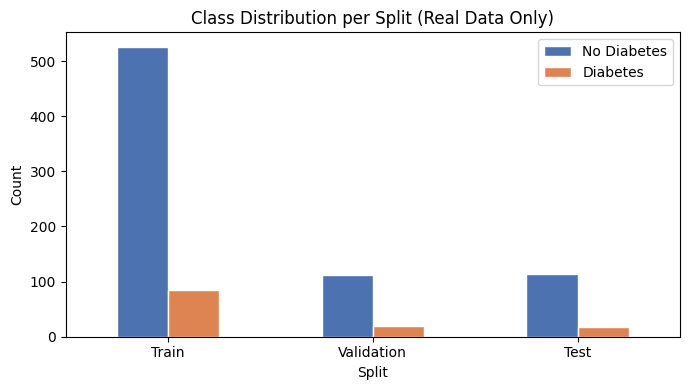

In [4]:
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]
FEATURES = X.columns.tolist()

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

summary = pd.DataFrame([
    {'Split': n, 'Rows': len(s), 'Diabetes': int(s.sum()),
     'No Diabetes': int((s==0).sum()), '% Positive': round(s.mean()*100, 1)}
    for n, s in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]
]).set_index('Split')
print(summary)

summary[['No Diabetes','Diabetes']].plot(
    kind='bar', figsize=(7, 4), color=['#4C72B0','#DD8452'], edgecolor='white'
)
plt.title('Class Distribution per Split (Real Data Only)')
plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 5. Feature Scaling

StandardScaler is **fit on the training set only**, then applied to val/test.

In [5]:
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train_raw)
X_val_s   = scaler.transform(X_val_raw)
X_test_s  = scaler.transform(X_test_raw)
print(f'Scaled — Train: {X_train_s.shape}  Val: {X_val_s.shape}  Test: {X_test_s.shape}')

Scaled — Train: (611, 14)  Val: (131, 14)  Test: (131, 14)


## 6. SMOTE — Balance the Training Set

SMOTE creates synthetic minority-class samples **inside the training set only**.  Validation and test remain untouched real data.

                 Before SMOTE  After SMOTE
Diabetes_binary                           
No Diabetes               526          526
Diabetes                   85          526


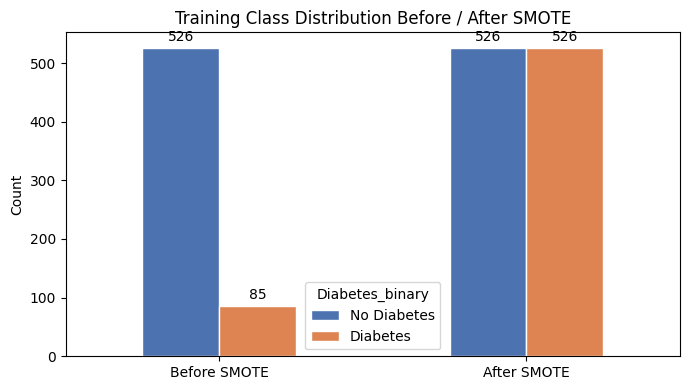

In [6]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_s, y_train)

before = pd.Series(y_train).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
after  = pd.Series(y_train_bal).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
smote_df = pd.DataFrame({'Before SMOTE': before, 'After SMOTE': after})
print(smote_df)

ax = smote_df.T.plot(kind='bar', figsize=(7, 4),
                     color=['#4C72B0','#DD8452'], edgecolor='white')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
plt.title('Training Class Distribution Before / After SMOTE')
plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 7. Train 4 Individual Models

All models trained on SMOTE-balanced training data.  
Ensemble is built **after** validation, using only the best 3 performers.

| # | Model | Strategy |
|---|---|---|
| 1 | Logistic Regression | Fixed hyperparams, balanced class weights |
| 2 | Random Forest | RandomizedSearchCV — 15 iter, 3-fold, F1 |
| 3 | XGBoost | RandomizedSearchCV — 15 iter, 3-fold, F1 |
| 4 | LightGBM | RandomizedSearchCV — 15 iter, 3-fold, F1 |

In [7]:
individual_models = {}

# 1. Logistic Regression
individual_models['Logistic Regression'] = LogisticRegression(
    max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE
)
individual_models['Logistic Regression'].fit(X_train_bal, y_train_bal)
print('Trained: Logistic Regression')

neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())
scale_pos = neg / pos

search_spaces = {
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [100,200,300,500], 'max_depth': [None,8,12,16,20],
         'min_samples_split': [2,5,10], 'min_samples_leaf': [1,2,4]}
    ),
    'XGBoost': (
        XGBClassifier(scale_pos_weight=scale_pos, eval_metric='logloss',
                      random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [100,200,400], 'max_depth': [3,5,7,9],
         'learning_rate': [0.01,0.05,0.1,0.2],
         'subsample': [0.7,0.8,1.0], 'colsample_bytree': [0.7,0.8,1.0]}
    ),
    'LightGBM': (
        LGBMClassifier(is_unbalance=True, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        {'n_estimators': [100,200,400], 'max_depth': [-1,5,10,15],
         'learning_rate': [0.01,0.05,0.1], 'num_leaves': [15,31,63]}
    ),
}

for name, (estimator, param_dist) in search_spaces.items():
    search = RandomizedSearchCV(
        estimator, param_dist, n_iter=15, cv=3,
        scoring='f1', random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X_train_bal, y_train_bal)
    individual_models[name] = search.best_estimator_
    print(f'Tuned {name}  |  best CV F1: {search.best_score_:.4f}')
    print(f'  params: {search.best_params_}')

print('\nAll 4 individual models trained.')

Trained: Logistic Regression
Tuned Random Forest  |  best CV F1: 0.8931
  params: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 20}
Tuned XGBoost  |  best CV F1: 0.8747
  params: {'subsample': 0.7, 'n_estimators': 100, 'max_depth': 7, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
Tuned LightGBM  |  best CV F1: 0.8624
  params: {'num_leaves': 63, 'n_estimators': 200, 'max_depth': -1, 'learning_rate': 0.1}

All 4 individual models trained.


## 8. Validation on STEPS & Model Selection

**Step 1** — Evaluate all 4 individual models on the STEPS validation set.  
**Step 2** — Select top 3 by **Validation F1** (primary) — Recall shown as clinical priority metric.  
**Step 3** — Build Soft Voting Ensemble from those top 3.  
**Step 4** — Final 4 candidates: top-3 individual + ensemble → select best by **Validation F1**.

Individual Model Validation Results (sorted by F1):
                     Recall      F1  Accuracy  Precision  ROC-AUC
Logistic Regression  0.8947  0.4789    0.7176     0.3269   0.8242
XGBoost              0.4737  0.4000    0.7939     0.3462   0.7679
Random Forest        0.3684  0.3784    0.8244     0.3889   0.7953
LightGBM             0.3158  0.3529    0.8321     0.4000   0.7834

Top 3 selected for ensemble → ['Logistic Regression', 'XGBoost', 'Random Forest']
Ensemble built: Ensemble (Logistic + XGBoost + Random)

Final Candidates — Validation Results (sorted by F1):
                                        Recall      F1  Accuracy  Precision  ROC-AUC
Logistic Regression                     0.8947  0.4789    0.7176     0.3269   0.8242
Ensemble (Logistic + XGBoost + Random)  0.5263  0.4255    0.7939     0.3571   0.8261
XGBoost                                 0.4737  0.4000    0.7939     0.3462   0.7679
Random Forest                           0.3684  0.3784    0.8244     0.3889   0.7953


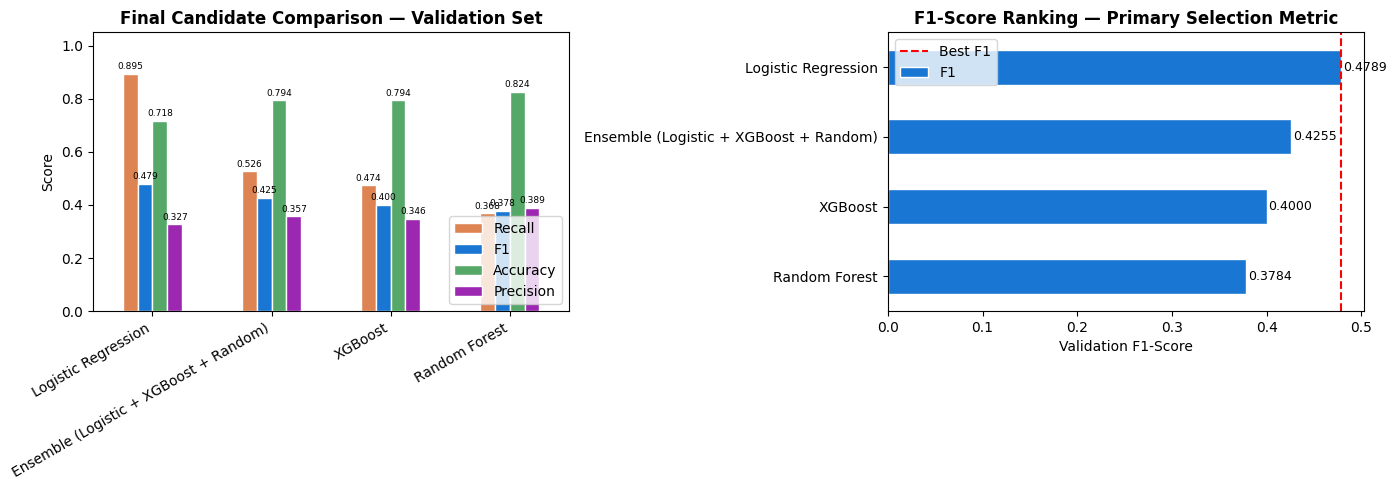

In [8]:
def evaluate(model, X, y, threshold=0.5):
    proba = model.predict_proba(X)[:, 1]
    pred  = (proba >= threshold).astype(int)
    return {
        'Recall':    round(recall_score(y, pred, zero_division=0), 4),   # clinical priority
        'F1':        round(f1_score(y, pred, zero_division=0), 4),       # selection metric
        'Accuracy':  round(accuracy_score(y, pred), 4),
        'Precision': round(precision_score(y, pred, zero_division=0), 4),
        'ROC-AUC':   round(roc_auc_score(y, proba), 4),
    }

# ── Step 1: Evaluate 4 individual models ─────────────────────────────────────
indiv_results = {n: evaluate(m, X_val_s, y_val) for n, m in individual_models.items()}
indiv_df = pd.DataFrame(indiv_results).T.sort_values('F1', ascending=False)
print('Individual Model Validation Results (sorted by F1):')
print(indiv_df.to_string())

# ── Step 2: Top 3 by F1 ───────────────────────────────────────────────────────
top3_names = indiv_df.nlargest(3, 'F1').index.tolist()
print(f'\nTop 3 selected for ensemble → {top3_names}')

# ── Step 3: Build Soft Voting Ensemble ───────────────────────────────────────
ensemble = VotingClassifier(
    estimators=[(n.lower().replace(' ','_').replace('/','_'), individual_models[n])
                for n in top3_names],
    voting='soft', n_jobs=1
)
ensemble.fit(X_train_bal, y_train_bal)
ensemble_label = f'Ensemble ({" + ".join(n.split()[0] for n in top3_names)})'
print(f'Ensemble built: {ensemble_label}')

# ── Step 4: Final 4 candidates ────────────────────────────────────────────────
final_models = {n: individual_models[n] for n in top3_names}
final_models[ensemble_label] = ensemble

final_results = {n: evaluate(m, X_val_s, y_val) for n, m in final_models.items()}
val_df = pd.DataFrame(final_results).T.sort_values('F1', ascending=False)
print('\nFinal Candidates — Validation Results (sorted by F1):')
print(val_df.to_string())
print('\nClinical priority: Recall  |  Selection metric: F1  |  Supporting: Accuracy, Precision')

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

val_df[['Recall','F1','Accuracy','Precision']].plot(
    kind='bar', ax=axes[0],
    color=['#DD8452','#1976D2','#55A868','#9C27B0'], edgecolor='white'
)
axes[0].set_title('Final Candidate Comparison — Validation Set', fontweight='bold')
axes[0].set_ylabel('Score'); axes[0].set_ylim(0, 1.05)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].legend(loc='lower right')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.3f', fontsize=6.5, padding=2)

val_df['F1'].sort_values().plot(kind='barh', ax=axes[1], color='#1976D2', edgecolor='white')
axes[1].set_title('F1-Score Ranking — Primary Selection Metric', fontweight='bold')
axes[1].set_xlabel('Validation F1-Score')
axes[1].axvline(val_df['F1'].max(), color='red', linestyle='--', lw=1.5, label='Best F1')
axes[1].legend()
for i, (idx, v) in enumerate(val_df['F1'].sort_values().items()):
    axes[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)

plt.tight_layout(); plt.show()

## 9. Threshold Tuning

**Clinical priority: Recall.**  
Sweep thresholds on the STEPS validation set. Select the threshold that **maximises Recall** subject to F1 ≥ 0.35.  
In healthcare, missing a true diabetic (false negative) is more costly than a false alarm.

Best model selected: Logistic Regression
  Val F1       : 0.4789  ← selection metric
  Val Recall   : 0.8947  ← clinical priority
  Val Accuracy : 0.7176
  Val Precision: 0.3269

Chosen threshold : 0.33
  Recall         : 0.9474  ← maximised
  F1             : 0.3564  (≥ floor 0.35)
  Precision      : 0.2195


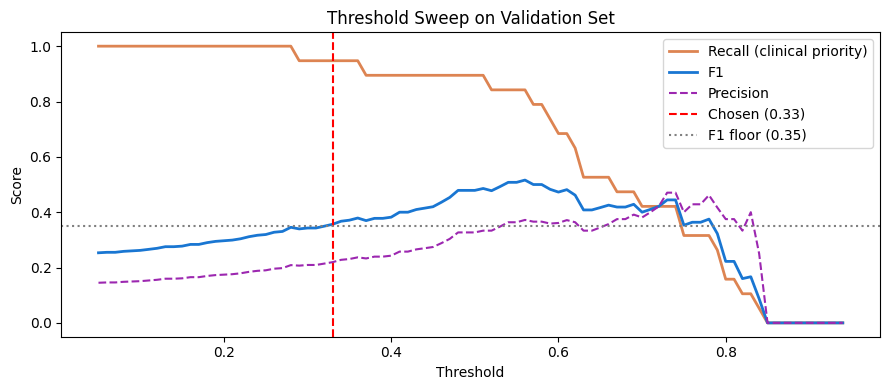

In [9]:
# Select best model by validation F1
best_name  = val_df['F1'].idxmax()
best_model = final_models[best_name]
print(f'Best model selected: {best_name}')
print(f'  Val F1       : {val_df.loc[best_name,"F1"]:.4f}  ← selection metric')
print(f'  Val Recall   : {val_df.loc[best_name,"Recall"]:.4f}  ← clinical priority')
print(f'  Val Accuracy : {val_df.loc[best_name,"Accuracy"]:.4f}')
print(f'  Val Precision: {val_df.loc[best_name,"Precision"]:.4f}')

F1_FLOOR  = 0.35
proba_val = best_model.predict_proba(X_val_s)[:, 1]
thr_rows  = []
for t in np.arange(0.05, 0.95, 0.01):
    pred = (proba_val >= t).astype(int)
    thr_rows.append({'Threshold': round(t, 2),
                     'Recall':    recall_score(y_val, pred, zero_division=0),
                     'Precision': precision_score(y_val, pred, zero_division=0),
                     'F1':        f1_score(y_val, pred, zero_division=0)})
thr_df     = pd.DataFrame(thr_rows)
acceptable = thr_df[thr_df['F1'] >= F1_FLOOR]

if len(acceptable) == 0:
    chosen_threshold = 0.5
    print(f'No threshold meets F1 >= {F1_FLOOR}. Using default 0.5.')
else:
    best_thr = acceptable.loc[acceptable['Recall'].idxmax()]
    chosen_threshold = best_thr['Threshold']
    print(f'\nChosen threshold : {chosen_threshold:.2f}')
    print(f'  Recall         : {best_thr["Recall"]:.4f}  ← maximised')
    print(f'  F1             : {best_thr["F1"]:.4f}  (≥ floor {F1_FLOOR})')
    print(f'  Precision      : {best_thr["Precision"]:.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thr_df['Threshold'], thr_df['Recall'],    label='Recall (clinical priority)', color='#DD8452', lw=2)
ax.plot(thr_df['Threshold'], thr_df['F1'],        label='F1',        color='#1976D2', lw=2)
ax.plot(thr_df['Threshold'], thr_df['Precision'], label='Precision', color='#9C27B0', lw=1.5, linestyle='--')
ax.axvline(chosen_threshold, color='red', linestyle='--', lw=1.5, label=f'Chosen ({chosen_threshold:.2f})')
ax.axhline(F1_FLOOR, color='gray', linestyle=':', label=f'F1 floor ({F1_FLOOR})')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold Sweep on Validation Set')
ax.legend(); plt.tight_layout(); plt.show()

## 10. Final Test Evaluation

Test results  |  Logistic Regression  (threshold = 0.33)

  Recall       0.8889 ← clinical priority
  F1           0.3019 ← selection metric
  Accuracy     0.4351
  Precision    0.1818
  ROC-AUC      0.7734

              precision    recall  f1-score   support

 No Diabetes       0.95      0.36      0.53       113
    Diabetes       0.18      0.89      0.30        18

    accuracy                           0.44       131
   macro avg       0.57      0.63      0.41       131
weighted avg       0.85      0.44      0.49       131



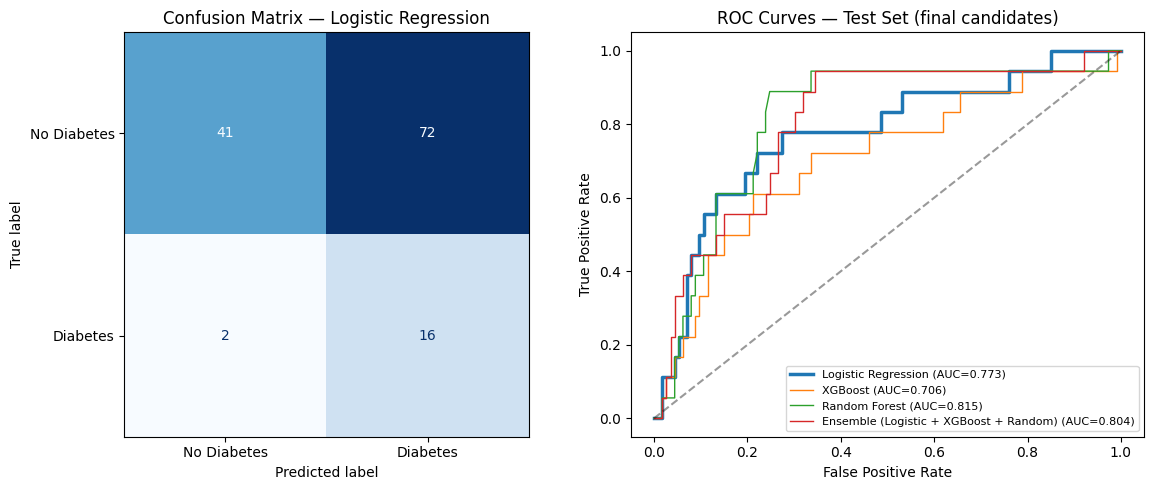

In [10]:
proba_test = best_model.predict_proba(X_test_s)[:, 1]
y_pred     = (proba_test >= chosen_threshold).astype(int)

test_metrics = {
    'Recall':    recall_score(y_test, y_pred, zero_division=0),
    'F1':        f1_score(y_test, y_pred, zero_division=0),
    'Accuracy':  accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_test, proba_test),
}
print(f'Test results  |  {best_name}  (threshold = {chosen_threshold:.2f})')
print()
for k, v in test_metrics.items():
    marker = ' ← clinical priority' if k == 'Recall' else (' ← selection metric' if k == 'F1' else '')
    print(f'  {k:<12s} {v:.4f}{marker}')
print()
print(classification_report(y_test, y_pred, target_names=['No Diabetes','Diabetes']))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Diabetes','Diabetes']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {best_name}')

for name, m in final_models.items():
    p = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    lw  = 2.5 if name == best_name else 1.0
    axes[1].plot(fpr, tpr, lw=lw, label=f'{name} (AUC={auc:.3f})')
axes[1].plot([0,1],[0,1],'k--', alpha=0.4)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves — Test Set (final candidates)')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 11. SHAP Explainability

SHAP quantifies each feature's contribution to every prediction.  
TreeExplainer is used for tree-based models; if the best model is Logistic Regression or the Ensemble, SHAP is computed on the **LightGBM component**.

In [11]:
TREE_MODELS = ['LightGBM','XGBoost','Random Forest']

if best_name in TREE_MODELS:
    shap_model      = best_model
    shap_model_name = best_name
else:
    tree_candidates = [n for n in TREE_MODELS if n in individual_models]
    shap_model_name = indiv_df.loc[indiv_df.index.isin(tree_candidates), 'F1'].idxmax()
    shap_model      = individual_models[shap_model_name]
    shap_model_name += ' (SHAP proxy — best tree)'

print(f'SHAP computed on: {shap_model_name}')
explainer   = shap.TreeExplainer(shap_model)
shap_values = explainer(X_test_s)

if shap_values.values.ndim == 3:
    sv = shap_values[:, :, 1]  # extract class-1 (diabetes)
else:
    sv = shap_values

print(f'SHAP values shape: {sv.values.shape}')

SHAP computed on: XGBoost (SHAP proxy — best tree)
SHAP values shape: (131, 14)


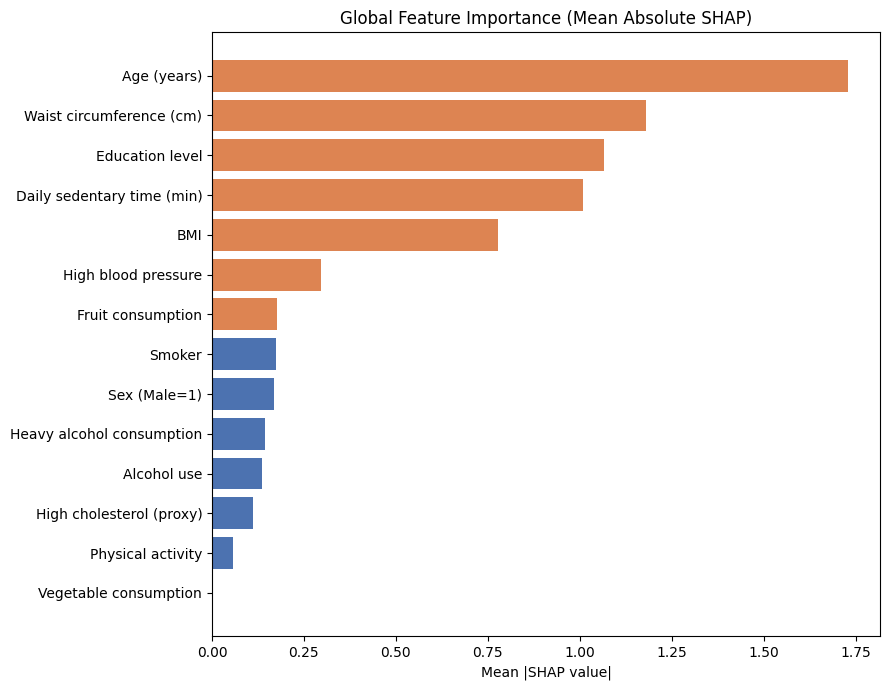

In [12]:
mean_shap = pd.Series(
    np.abs(sv.values).mean(axis=0), index=FEATURES
).sort_values(ascending=True)

labels_mapped = [FEATURE_LABELS.get(f, f) for f in mean_shap.index]
palette = ['#DD8452' if v > mean_shap.median() else '#4C72B0' for v in mean_shap]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(labels_mapped, mean_shap.values, color=palette)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('Global Feature Importance (Mean Absolute SHAP)')
plt.tight_layout(); plt.show()

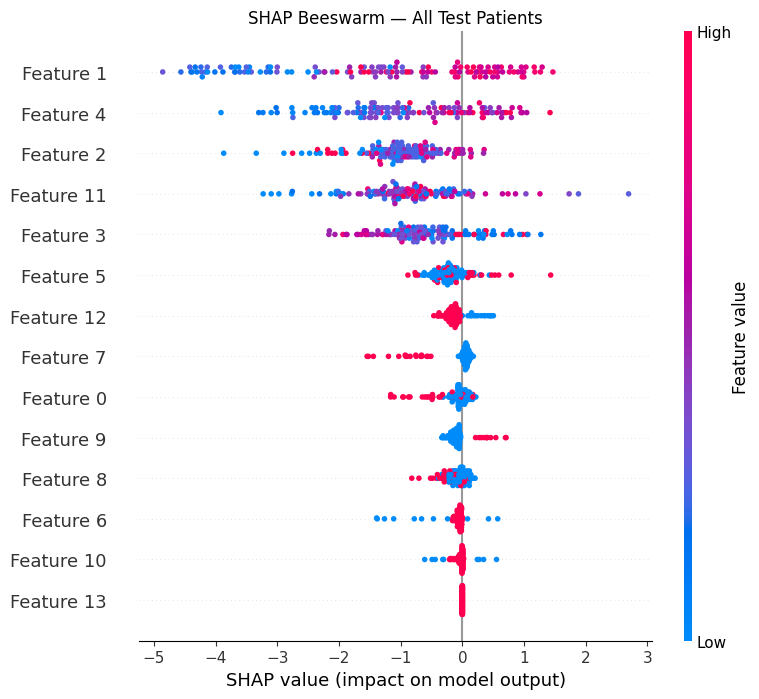

In [13]:
shap.plots.beeswarm(sv, max_display=19, show=False)
plt.title('SHAP Beeswarm — All Test Patients')
plt.tight_layout(); plt.show()

## 12. Risk Categories

| Risk Level | Probability |
|---|---|
| Low | < 30 % |
| Moderate | 30 % – 70 % |
| High | > 70 % |

Risk distribution on Test Set:
Risk Level
Low         38
Moderate    66
High        27
Name: count, dtype: int64


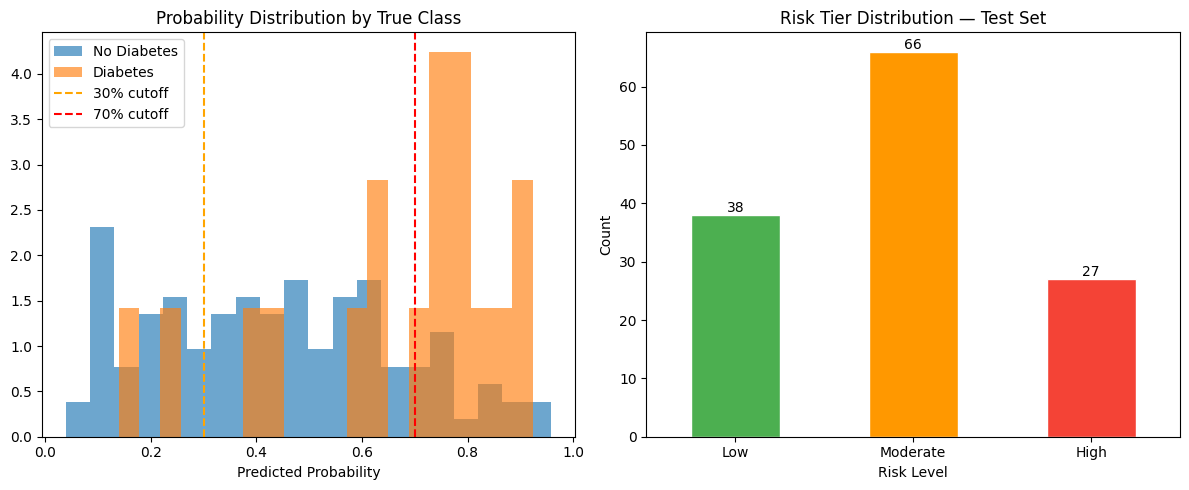

In [14]:
def risk_label(prob):
    if prob < 0.30:   return 'Low'
    elif prob < 0.70: return 'Moderate'
    else:             return 'High'

test_report = X_test_raw.copy().reset_index(drop=True)
test_report['True Label']  = y_test.values
test_report['Probability'] = proba_test.round(3)
test_report['Risk Level']  = test_report['Probability'].apply(risk_label)
test_report['Prediction']  = y_pred

risk_dist = test_report['Risk Level'].value_counts().reindex(['Low','Moderate','High'])
print('Risk distribution on Test Set:')
print(risk_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for lab, grp in test_report.groupby('True Label'):
    axes[0].hist(grp['Probability'], bins=20, alpha=0.65,
                 label=['No Diabetes','Diabetes'][int(lab)], density=True)
axes[0].axvline(0.30, color='orange', linestyle='--', label='30% cutoff')
axes[0].axvline(0.70, color='red',    linestyle='--', label='70% cutoff')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_title('Probability Distribution by True Class')
axes[0].legend()

risk_dist.plot(kind='bar', ax=axes[1],
               color=[RISK_COLORS[r] for r in risk_dist.index],
               edgecolor='white')
for p in axes[1].patches:
    axes[1].annotate(str(int(p.get_height())),
                     (p.get_x()+p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')
axes[1].set_title('Risk Tier Distribution — Test Set')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(risk_dist.index, rotation=0)
plt.tight_layout(); plt.show()

## 13. Patient Dashboard (4-Panel)

Four-panel report for any individual patient:
1. **Patient Result** — predicted probability + risk level gauge
2. **Main Reasons** — top SHAP drivers (red = increases risk, green = reduces risk)
3. **Group Insight** — donut chart of SHAP contribution by feature category
4. **Actionable Recommendations** — Gemini-generated personalised health education

In [15]:
def pretty(feat):
    return FEATURE_LABELS.get(feat, feat.replace('_',' ').title())

def patient_dashboard(patient_idx, use_gemini=True):
    prob       = proba_test[patient_idx]
    risk       = risk_label(prob)
    true_label = y_test.values[patient_idx]
    shap_vals  = sv.values[patient_idx]
    row        = X_test_raw.iloc[patient_idx]

    order     = np.argsort(np.abs(shap_vals))[::-1]
    top_feats = [FEATURES[i] for i in order[:4]]
    top_vals  = [shap_vals[i]  for i in order[:4]]

    gc = {}
    for grp, feats in FEATURE_GROUPS.items():
        idxs = [FEATURES.index(f) for f in feats if f in FEATURES]
        gc[grp] = float(np.abs(shap_vals[idxs]).sum())
    gc_total = sum(gc.values()) or 1
    gc_pct   = {k: v/gc_total*100 for k, v in gc.items()}

    risk_feats  = [FEATURE_LABELS.get(FEATURES[i], FEATURES[i])
                   for i in np.argsort(shap_vals)[::-1][:4] if shap_vals[i] > 0]
    prot_feats  = [FEATURE_LABELS.get(FEATURES[i], FEATURES[i])
                   for i in np.argsort(shap_vals)[:4] if shap_vals[i] < 0]
    patient_profile = {
        'Age':         int(row.get('Age', 0)),
        'BMI':         round(float(row.get('BMI', 0)), 1),
        'HighBP':      int(row.get('HighBP', 0)),
        'PhysActive':  int(row.get('PhysActivity', 0)),
        'Smoker':      int(row.get('Smoker', 0)),
    }

    if use_gemini and gemini_client:
        gem = get_gemini_recommendations(prob, risk, patient_profile, risk_feats, prot_feats)
    else:
        gem = {
            'explanation': f'Your predicted diabetes risk is {prob*100:.0f}% ({risk} level). '
                           'Key factors from your health and lifestyle profile contribute to this result.',
            'recommendations': [
                'Maintain a balanced diet with more vegetables and whole grains',
                'Exercise at least 150 minutes per week (e.g. brisk walking)',
                'Monitor blood pressure and blood sugar regularly',
                'Consult a healthcare professional for personalised guidance',
            ],
            'safety_reminder': 'This is for educational awareness only — not a medical diagnosis.',
        }

    recs = gem.get('recommendations', [])[:4]

    risk_color   = RISK_COLORS[risk]
    group_colors = ['#1976D2','#FF9800','#4CAF50']
    rec_colors   = ['#1976D2','#43A047','#E53935','#FB8C00']

    fig = plt.figure(figsize=(18, 7))
    fig.patch.set_facecolor('#FAFAFA')
    gs  = fig.add_gridspec(1, 4, wspace=0.38)

    # Panel 1: Patient Result
    ax1 = fig.add_subplot(gs[0])
    ax1.set_facecolor('white'); ax1.axis('off')
    ax1.text(0.5, 0.93, 'Patient Result', ha='center', va='top',
             fontsize=13, fontweight='bold', transform=ax1.transAxes)
    ax1.text(0.5, 0.66, f'{prob*100:.0f}%', ha='center', va='center',
             fontsize=46, fontweight='bold', color='#1A1A2E', transform=ax1.transAxes)
    ax1.text(0.5, 0.48, f'{risk} Risk', ha='center', va='center',
             fontsize=18, fontweight='bold', color=risk_color, transform=ax1.transAxes)
    for x0, x1, c in [(0.05,0.32,'#4CAF50'),(0.32,0.58,'#FF9800'),(0.58,0.95,'#F44336')]:
        ax1.barh(0.30, x1-x0, left=x0, height=0.06, color=c, transform=ax1.transAxes)
    needle = min(0.05 + prob*0.90, 0.93)
    ax1.annotate('', xy=(needle, 0.37), xytext=(needle, 0.45),
                 xycoords='axes fraction', textcoords='axes fraction',
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))
    ax1.text(0.5, 0.14, 'Predicted diabetes risk probability',
             ha='center', va='center', fontsize=8, color='gray', transform=ax1.transAxes)
    ax1.set_xlim(0,1); ax1.set_ylim(0,1)
    for sp in ax1.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    # Panel 2: Main Reasons (SHAP bars)
    ax2 = fig.add_subplot(gs[1])
    ax2.set_facecolor('white')
    bar_colors = ['#F44336' if v > 0 else '#4CAF50' for v in top_vals]
    y_pos = list(range(len(top_feats)-1, -1, -1))
    ax2.barh(y_pos, top_vals, color=bar_colors, height=0.55)
    labels = [f'{pretty(f)}\n{"increases" if v>0 else "reduces"} risk'
              for f, v in zip(top_feats, top_vals)]
    ax2.set_yticks(y_pos); ax2.set_yticklabels(labels, fontsize=8.5)
    ax2.axvline(0, color='black', linewidth=0.8)
    ax2.set_title('Main Reasons', fontsize=13, fontweight='bold', pad=10)
    ax2.set_xlabel('SHAP value (impact on risk)')
    for i, y in enumerate(y_pos):
        cc = '#F44336' if top_vals[i] > 0 else '#4CAF50'
        ax2.annotate(str(i+1), xy=(ax2.get_xlim()[0], y), fontsize=9,
                     color='white', fontweight='bold',
                     bbox=dict(boxstyle='circle,pad=0.25', fc=cc, ec='none'))
    for sp in ax2.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    # Panel 3: Group Insight (donut)
    ax3 = fig.add_subplot(gs[2])
    ax3.set_facecolor('white')
    grp_names = list(gc_pct.keys())
    grp_vals  = [gc_pct[g] for g in grp_names]
    wedges, _ = ax3.pie(
        grp_vals, colors=group_colors, startangle=90, counterclock=False,
        wedgeprops={'width':0.5, 'edgecolor':'white', 'linewidth':2}
    )
    ax3.legend(wedges, [f'{g}: {v:.0f}%' for g,v in zip(grp_names, grp_vals)],
               loc='lower center', bbox_to_anchor=(0.5,-0.22), fontsize=8, frameon=False)
    ax3.set_title('Group Insight', fontsize=13, fontweight='bold')
    top_grp = max(gc_pct, key=gc_pct.get)
    ax3.text(0.5, -0.34, f'{top_grp} is the main\ncategory driving\nthis risk',
             ha='center', fontsize=8.5, color='#444444', transform=ax3.transAxes)
    for sp in ax3.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    # Panel 4: Gemini Recommendations
    ax4 = fig.add_subplot(gs[3])
    ax4.set_facecolor('white'); ax4.axis('off')
    ax4.text(0.5, 0.97, 'Actionable\nRecommendation',
             ha='center', va='top', fontsize=12, fontweight='bold', transform=ax4.transAxes)

    import textwrap
    explanation = gem.get('explanation','')
    lines = textwrap.wrap(explanation, width=42)
    for li, line in enumerate(lines[:3]):
        ax4.text(0.05, 0.86 - li*0.055, line, ha='left', va='center',
                 fontsize=7.5, color='#333333', style='italic', transform=ax4.transAxes)

    for i, rec in enumerate(recs[:4]):
        yr = 0.66 - i * 0.155
        ax4.text(0.09, yr, str(i+1), ha='center', va='center',
                 fontsize=10, color='white', fontweight='bold', transform=ax4.transAxes,
                 bbox=dict(boxstyle='circle,pad=0.3', fc=rec_colors[i], ec='none'))
        wrapped = textwrap.wrap(rec, width=35)
        for wi, wline in enumerate(wrapped[:2]):
            ax4.text(0.18, yr - wi*0.045, wline, ha='left', va='center',
                     fontsize=8, color='#1A1A2E', transform=ax4.transAxes)
        ax4.plot([0.0,1.0],[yr-0.065,yr-0.065], color='#EEEEEE',
                 lw=1, transform=ax4.transAxes)

    safety = gem.get('safety_reminder','')
    ax4.text(0.5, 0.03, safety[:70], ha='center', va='bottom',
             fontsize=7, color='#999999', style='italic', transform=ax4.transAxes)
    for sp in ax4.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    fig.suptitle(
        f'Patient #{patient_idx}   |   True label: {["No Diabetes","Diabetes"][true_label]}   |   STEPS Cambodia Cohort',
        fontsize=10, color='#555555', y=1.01
    )
    plt.show()
    return prob, risk

print('patient_dashboard() function defined.')

patient_dashboard() function defined.


High-risk example: patient #7


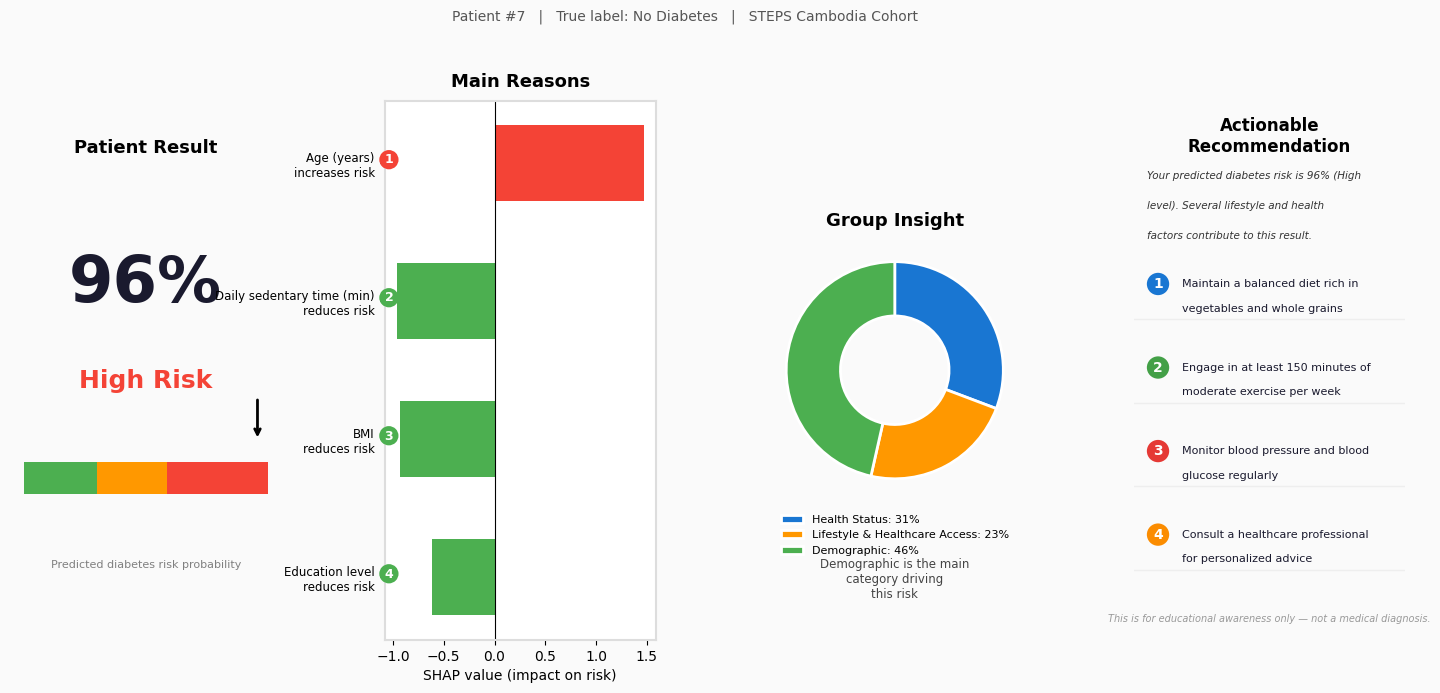

Moderate-risk example: patient #2


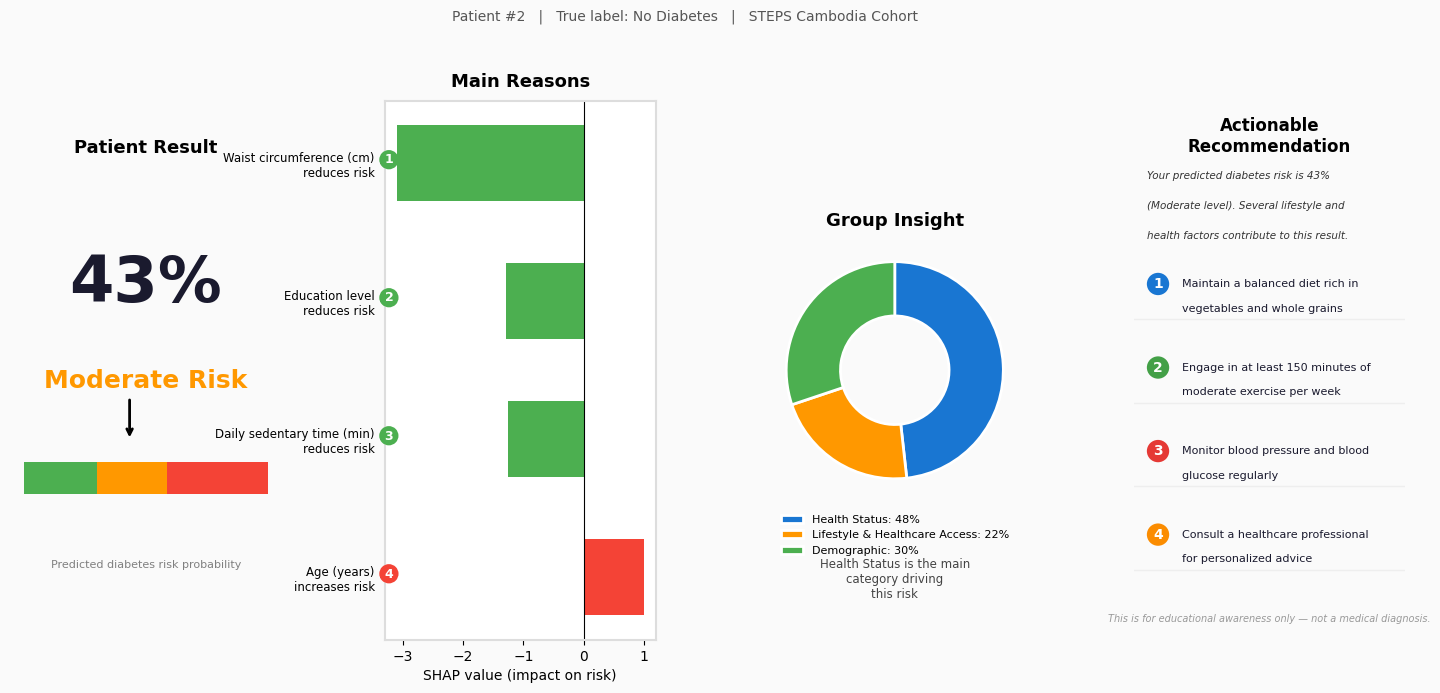

In [16]:
# High-risk patient
high_risk_idx = int(np.argmax(proba_test))
print(f'High-risk example: patient #{high_risk_idx}')
patient_dashboard(high_risk_idx)

# Moderate-risk patient
mod_mask = (proba_test >= 0.30) & (proba_test < 0.60)
if mod_mask.any():
    mid_idx = int(np.where(mod_mask)[0][0])
    print(f'Moderate-risk example: patient #{mid_idx}')
    patient_dashboard(mid_idx)

In [17]:
print('=' * 42)
print('     FINAL TEST SET REPORT — STEPS')
print('=' * 42)
print(f'Model      : {best_name}')
print(f'Threshold  : {chosen_threshold:.2f}')
for k, v in test_metrics.items():
    print(f'{k:<12s}: {v:.4f}')
print()
print('Risk tier breakdown:')
print(test_report['Risk Level'].value_counts().reindex(['High','Moderate','Low']))

     FINAL TEST SET REPORT — STEPS
Model      : Logistic Regression
Threshold  : 0.33
Recall      : 0.8889
F1          : 0.3019
Accuracy    : 0.4351
Precision   : 0.1818
ROC-AUC     : 0.7734

Risk tier breakdown:
Risk Level
High        27
Moderate    66
Low         38
Name: count, dtype: int64


## 14. Save Best Model & Scaler

In [18]:
joblib.dump(best_model,       'best_model.pkl')
joblib.dump(scaler,           'scaler.pkl')
joblib.dump(chosen_threshold, 'threshold.pkl')
joblib.dump(FEATURES,         'feature_names.pkl')
print(f'Saved: best_model.pkl    ({best_name})')
print(f'Saved: scaler.pkl')
print(f'Saved: threshold.pkl     ({chosen_threshold:.2f})')
print(f'Saved: feature_names.pkl ({len(FEATURES)} features)')

Saved: best_model.pkl    (Logistic Regression)
Saved: scaler.pkl
Saved: threshold.pkl     (0.33)
Saved: feature_names.pkl (14 features)
